# 07 — Chuẩn hoá và gộp dữ liệu 8 thành phố

Notebook này làm 5 việc, theo đúng thứ tự:

1. **Chuẩn hoá Lucknow và Jaipur**: hai thành phố này mới chỉ có file ở `data/interim/`, chưa có `*_clean.csv` trong `data/processed/`. Tạo file đó và đổi cách đánh dấu outlier về cùng quy tắc với 6 thành phố còn lại (IQR theo tháng, chỉ đánh dấu).
2. **Áp quyết định chung "bỏ cột Xylene"** cho Amritsar (file cũ còn giữ Xylene).
3. **Kiểm tra điểm nghi lỗi cảm biến cho cả 8 thành phố** bằng đúng quy trình nhóm đã dùng cho Lucknow/Jaipur (notebook 02, mục EX4.2), để mọi thành phố được đối xử như nhau.
4. **Gộp 8 thành phố** thành `data/processed/air_quality_8cities.csv` và kiểm tra bằng `assert`.
5. **Sinh bảng tóm tắt làm sạch** `reports/cleaning_summary_8cities.csv` và biểu đồ missing còn lại.

Quy ước: ngoài các điểm nghi lỗi cảm biến ở bước 3 (đặt NaN, có ghi lại giá trị gốc trong `reports/suspect_points_8cities.csv`), notebook này **không sửa giá trị nồng độ** của thành phố nào, chỉ đổi tên/đánh dấu cột và bỏ cột Xylene.

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import (flag_outliers_iqr, flag_flatline_zeros, load_and_split_city, validity_checks,
                   check_consistency, check_duplicates, AQI_LABELS)
from gap_utils import contextual_ratio

RAW       = "../data/raw/city_day.csv"
INTERIM   = "../data/interim"
PROCESSED = "../data/processed"
REPORTS   = "../reports"
os.makedirs(f"{REPORTS}/figures", exist_ok=True)

CITIES = ["Delhi", "Gurugram", "Lucknow", "Jaipur",
          "Bengaluru", "Amritsar", "Chennai", "Hyderabad"]

# 11 chất sau khi bỏ Xylene (quyết định chung: Xylene thiếu 100% ở 4/8 thành phố)
POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
              "CO", "SO2", "O3", "Benzene", "Toluene"]

PM_RATIO        = 1.2   # PM2.5 > 1,2 x PM10 thì coi là vô lý (PM10 đã gồm cả PM2.5) — ngưỡng nhóm Jaipur đã dùng
MISSING_MAX_PCT = 60    # quy ước nhóm: cột (trong 1 thành phố) thiếu < 60% thì còn dùng được làm biến
CTX_THR         = 2.5   # ngưỡng "ngữ cảnh" và tập mùa cao điểm: lấy đúng như notebook 02
WINTER          = {10, 11, 12, 1, 2}
GASES           = ["PM10", "NO", "NO2", "NOx", "CO", "SO2", "O3", "Benzene", "Toluene", "NH3"]

## Bước 1 — Lucknow và Jaipur: tạo file `*_clean.csv`

Hai thành phố này trước đó dùng một bộ cờ outlier riêng (`*_iqr_flag`, `*_ctx_flag`, tính trên toàn bộ chuỗi),
khác 6 thành phố còn lại (`<cột>_is_outlier`, IQR **theo từng tháng**). Nếu để nguyên thì gộp lại sẽ lệch cột.

Cách xử lý:
- Giữ nguyên toàn bộ **giá trị** đã làm sạch (flatline → NaN, nội suy gap ≤ 14 ngày, các điểm nghi lỗi cảm biến đã đặt NaN).
- Bỏ các cột cờ riêng, chạy lại `flag_outliers_iqr()` của `utils.py` để có `<cột>_is_outlier` cùng quy tắc.
- Giữ cột `suspect_sensor_error` (đánh dấu ngày bị đặt NaN vì nghi lỗi cảm biến).

In [2]:
def finalize_lucknow_jaipur(city):
    df = pd.read_csv(f"{INTERIM}/{city.lower()}_after_outliers.csv", parse_dates=["Date"])

    own_flags = [c for c in df.columns
                 if c.endswith(("_iqr_flag", "_ctx_flag")) or c == "pm25_gt_pm10_flag"]
    df = df.drop(columns=own_flags + [c for c in df.columns if c.startswith("Xylene") and c != "Xylene_was_missing"])

    df = flag_outliers_iqr(df, cols=POLLUTANTS)     # chỉ đánh dấu, không đổi giá trị
    df["suspect_sensor_error"] = df["suspect_sensor_error"].astype(bool)

    present  = [p for p in POLLUTANTS if p in df.columns]
    was_miss = [c for c in df.columns if c.endswith("_was_missing")]
    outl     = [f"{p}_is_outlier" for p in present]
    order = ["Date", "City"] + present + ["AQI", "AQI_Bucket"] + was_miss + outl + ["suspect_sensor_error"]
    return df[order].sort_values("Date").reset_index(drop=True)

for city in ["Lucknow", "Jaipur"]:
    out = finalize_lucknow_jaipur(city)
    out.to_csv(f"{PROCESSED}/{city.lower()}_clean.csv", index=False)
    n_flag = int(out[[c for c in out.columns if c.endswith('_is_outlier')]].sum().sum())
    print(f"{city}: {out.shape}  | cột PM10 có mặt: {'PM10' in out.columns} | tổng ô bị đánh dấu outlier: {n_flag}")

Lucknow: (2009, 38)  | cột PM10 có mặt: False | tổng ô bị đánh dấu outlier: 950


Jaipur: (1114, 40)  | cột PM10 có mặt: True | tổng ô bị đánh dấu outlier: 467


## Bước 2 — Amritsar: bỏ Xylene cho đúng quyết định chung

Amritsar là thành phố duy nhất còn giữ cột `Xylene`. Bỏ cột này (và các cột `Xylene_*` đi kèm) để 8 thành phố cùng một bộ cột.
Chạy lại notebook không gây lỗi vì chỉ bỏ cột nếu nó còn tồn tại.

In [3]:
am = pd.read_csv(f"{PROCESSED}/amritsar_clean.csv", parse_dates=["Date"])
xyl = [c for c in am.columns if c.startswith("Xylene")]
print("Cột Xylene* còn trong Amritsar:", xyl)
if xyl:
    am = am.drop(columns=xyl)
    am.to_csv(f"{PROCESSED}/amritsar_clean.csv", index=False)
    print("-> đã bỏ và lưu lại amritsar_clean.csv:", am.shape)

Cột Xylene* còn trong Amritsar: []


## Bước 3 — Điểm nghi lỗi cảm biến: cùng một quy trình cho cả 8 thành phố

Ở notebook 02, bạn làm Lucknow/Jaipur đã điều tra các điểm lớn nhất của **PM2.5** và **AQI** (top 5 mỗi cột) bằng 4 bằng chứng:
cao gấp mấy lần các ngày lân cận; có nằm trong mùa cao điểm (tháng 10–2) không; có chất khác cùng tăng không; và PM2.5 có vô lý so với PM10 không (PM2.5 > 1,5 × PM10).
Điểm nào **cô lập, trái mùa, các chất khác không tăng theo** hoặc **PM2.5 vô lý so với PM10** thì bị coi là *nghi lỗi* và đặt NaN (không nội suy). Ngày AQI đi cùng ngày PM2.5 nghi lỗi cũng bị đặt NaN theo.

Ở đây chạy **đúng luật đó** cho 6 thành phố còn lại. Cách làm:
- Kiểm chứng trước: chạy lại luật trên Lucknow/Jaipur và xác nhận ra đúng các ngày nhóm đã đặt NaN.
- 6 thành phố còn lại: điểm bị gợi ý "NGHI LỖI" → đặt NaN và ghi `suspect_sensor_error = True`; điểm "chưa rõ" → giữ nguyên.
- Mọi điểm được xét (cả bị đặt NaN lẫn giữ lại) kèm giá trị gốc và bằng chứng nằm trong `reports/suspect_points_8cities.csv`, để cả nhóm đọc và phản biện.
- Gọi là **"nghi lỗi"**, không phải "đã xác minh", vì chưa đối chiếu được nguồn CPCB.
- Chạy lại notebook không áp lại: thành phố nào đã có cột `suspect_sensor_error` thì bỏ qua.

In [4]:
def investigate(d, col, top=5, skip_pm25=(), extra_dates=()):
    """Luật điều tra y như notebook 02 (EX4.2). d: DataFrame có index là Date. Trả về bảng bằng chứng + gợi ý."""
    ratio  = contextual_ratio(d[col])
    others = [g for g in GASES if g in d.columns and d[g].notna().any()]
    R      = pd.DataFrame({g: contextual_ratio(d[g]) for g in others})
    has10  = "PM10" in d.columns and d["PM10"].notna().any()
    pm25_r = contextual_ratio(d["PM2.5"])
    pm10_r = contextual_ratio(d["PM10"]) if has10 else pd.Series(np.nan, index=d.index)
    skip   = set(skip_pm25)
    for t in skip: pm25_r[t] = np.nan          # điểm PM2.5 đã nghi lỗi thì không dùng làm bằng chứng
    dates  = list(d[col].nlargest(top).index)
    dates += [t for t in extra_dates if t in d.index and d.loc[t, col] == d.loc[t, col] and t not in dates]
    rows = []
    for t in dates:
        co      = [g for g in others if R.loc[t, g] >= 1.5]
        pm10_ok = has10 and pm10_r[t] == pm10_r[t] and pm10_r[t] >= 1.5
        expl    = (col == "AQI") and (pm10_ok or (np.nan_to_num(pm25_r[t], nan=-1) >= 1.5))
        p_ratio = d.loc[t, "PM2.5"] / d.loc[t, "PM10"] if has10 and d.loc[t, "PM10"] > 0 else np.nan
        winter  = t.month in WINTER
        if   col == "AQI" and t in skip and not pm10_ok:               goi_y = "NGHI LOI (theo PM2.5 nghi loi cung ngay)"
        elif col == "PM2.5" and p_ratio == p_ratio and p_ratio > 1.5:  goi_y = "NGHI LOI (PM2.5 > 1,5 x PM10)"
        elif winter and ratio[t] < 3:                                   goi_y = "that (mua cao diem)"
        elif expl or len(co) >= 3:                                      goi_y = "that (chat khac cung tang)"
        elif (not winter) and ratio[t] >= 4:                            goi_y = "NGHI LOI (co lap, trai mua)"
        else:                                                           goi_y = "chua ro -> giu + co"
        rows.append(dict(date=t, column=col, value_original=round(d.loc[t, col], 1),
                         gap_vs_neighbors=round(ratio[t], 1), month=t.month,
                         pm25_div_pm10=round(p_ratio, 2) if p_ratio == p_ratio else np.nan,
                         other_gases_up=f"{len(co)}/{R.loc[t].notna().sum()}", suggestion=goi_y))
    return pd.DataFrame(rows)

def run_rule(d):
    """PM2.5 trước, rồi AQI (kèm các ngày PM2.5 nghi lỗi). Trả về bảng bằng chứng."""
    r25 = investigate(d, "PM2.5")
    sus = [t for t in r25.loc[r25.suggestion.str.startswith("NGHI"), "date"]]
    rq  = investigate(d, "AQI", skip_pm25=sus, extra_dates=sus)
    return pd.concat([r25, rq], ignore_index=True)

# --- 3a. kiểm chứng trên Lucknow/Jaipur: luật phải ra đúng các ngày nhóm đã đặt NaN ở notebook 02
CAND = []
for city in ["Lucknow", "Jaipur"]:
    d = pd.read_csv(f"{INTERIM}/{city.lower()}_after_missing.csv", parse_dates=["Date"]).set_index("Date")
    res = run_rule(d)
    found = set(res.loc[res.suggestion.str.startswith("NGHI"), "date"])
    done  = set(pd.read_csv(f"{PROCESSED}/{city.lower()}_clean.csv", parse_dates=["Date"])
                .query("suspect_sensor_error").Date)
    assert found == done, f"{city}: luật ra {sorted(found)} khác các ngày đã đặt NaN {sorted(done)}"
    res["city"] = city
    res["action"] = np.where(res.suggestion.str.startswith("NGHI"), "đặt NaN (làm ở notebook 02)", "giữ nguyên")
    CAND.append(res)
    print(f"{city}: luật tái hiện đúng {len(done)} ngày nghi lỗi nhóm đã xử lý")

Lucknow: luật tái hiện đúng 4 ngày nghi lỗi nhóm đã xử lý


Jaipur: luật tái hiện đúng 1 ngày nghi lỗi nhóm đã xử lý


In [5]:
# --- 3b. áp cho 6 thành phố còn lại
APPLIED_NOW = False
for city in ["Delhi", "Gurugram", "Bengaluru", "Amritsar", "Chennai", "Hyderabad"]:
    path = f"{PROCESSED}/{city.lower()}_clean.csv"
    df = pd.read_csv(path, parse_dates=["Date"])
    if "suspect_sensor_error" in df.columns:
        print(f"{city}: đã áp trước đó -> bỏ qua")
        continue
    d = df.set_index("Date")
    res = run_rule(d)
    sus = res[res.suggestion.str.startswith("NGHI")]
    d["suspect_sensor_error"] = False
    for _, r in sus.iterrows():
        d.loc[r.date, r.column] = np.nan
        d.loc[r.date, "suspect_sensor_error"] = True
        if r.column == "AQI":
            d.loc[r.date, "AQI_Bucket"] = np.nan
    out = flag_outliers_iqr(d.reset_index(), cols=["PM2.5"])     # tính lại cờ sau khi bỏ điểm nghi lỗi (như Lucknow/Jaipur)
    out.to_csv(path, index=False)
    res["city"] = city
    res["action"] = np.where(res.suggestion.str.startswith("NGHI"), "đặt NaN", "giữ nguyên")
    CAND.append(res)
    APPLIED_NOW = True
    n_days = int(out.suspect_sensor_error.sum())
    print(f"{city}: {len(sus)} điểm (PM2.5: {(sus.column=='PM2.5').sum()}, AQI: {(sus.column=='AQI').sum()}) "
          f"nghi lỗi trên {n_days} ngày -> đã đặt NaN")

cols = ["city", "date", "column", "value_original", "gap_vs_neighbors", "month",
        "pm25_div_pm10", "other_gases_up", "suggestion", "action"]
if APPLIED_NOW:
    report = pd.concat(CAND, ignore_index=True)[cols].sort_values(["city", "column", "date"])
    report.to_csv(f"{REPORTS}/suspect_points_8cities.csv", index=False, encoding="utf-8-sig")
    print("Đã lưu reports/suspect_points_8cities.csv:", len(report), "dòng")
else:
    print("Không áp gì mới; giữ nguyên reports/suspect_points_8cities.csv")
report = pd.read_csv(f"{REPORTS}/suspect_points_8cities.csv")
report.groupby(["city", "action"]).size().unstack(fill_value=0).reindex(CITIES)

Delhi: đã áp trước đó -> bỏ qua
Gurugram: đã áp trước đó -> bỏ qua
Bengaluru: đã áp trước đó -> bỏ qua
Amritsar: đã áp trước đó -> bỏ qua
Chennai: đã áp trước đó -> bỏ qua
Hyderabad: đã áp trước đó -> bỏ qua
Không áp gì mới; giữ nguyên reports/suspect_points_8cities.csv


action,giữ nguyên,đặt NaN,đặt NaN (làm ở notebook 02)
city,,,
Delhi,10,0,0
Gurugram,7,5,0
Lucknow,4,0,6
Jaipur,9,0,2
Bengaluru,6,6,0
Amritsar,5,8,0
Chennai,8,4,0
Hyderabad,3,10,0


## Bước 4 — Gộp 8 thành phố

Quy tắc gộp:
- Giữ **tất cả** ngày mà mỗi thành phố có dữ liệu (không cắt về khoảng chung) — khi phân tích có thể lọc sau.
- `PM10` của Lucknow không có (bỏ vì thiếu 100%) → sau khi gộp là NaN, và `PM10_was_missing = True`.
- `*_is_outlier`: ô không có giá trị → `False` (cùng quy ước với `flag_outliers_iqr`).
- `suspect_sensor_error`: cả 8 thành phố đã qua cùng một bước kiểm tra (Bước 3).
- Thêm cột `pm25_gt_pm10_flag` dùng chung quy tắc cho cả 8 thành phố: PM2.5 > 1,2 × PM10. Để trống (`<NA>`) khi thiếu PM2.5 hoặc PM10 (Lucknow không có PM10 nên luôn trống). **Chỉ đánh dấu, không sửa giá trị.**

In [6]:
frames = []
for city in CITIES:
    df = pd.read_csv(f"{PROCESSED}/{city.lower()}_clean.csv", parse_dates=["Date"])
    df = df.drop(columns=[c for c in df.columns if c.startswith("Xylene")])
    frames.append(df)

merged = pd.concat(frames, ignore_index=True, sort=False)

for p in POLLUTANTS:                                   # cờ outlier: ô không có giá trị -> False
    merged[f"{p}_is_outlier"] = merged[f"{p}_is_outlier"].fillna(False).astype(bool)
for p in POLLUTANTS + ["AQI"]:                         # Lucknow không có cột PM10 -> coi là thiếu
    merged[f"{p}_was_missing"] = merged[f"{p}_was_missing"].fillna(True).astype(bool)
merged["suspect_sensor_error"] = merged["suspect_sensor_error"].astype(bool)

both = merged["PM2.5"].notna() & merged["PM10"].notna()
flag = (merged["PM2.5"] > PM_RATIO * merged["PM10"]).astype("boolean")
flag[~both] = pd.NA
merged["pm25_gt_pm10_flag"] = flag

order = (["Date", "City"] + POLLUTANTS + ["AQI", "AQI_Bucket"]
         + [f"{p}_was_missing" for p in POLLUTANTS + ["AQI"]]
         + [f"{p}_is_outlier" for p in POLLUTANTS]
         + ["pm25_gt_pm10_flag", "suspect_sensor_error"])
merged = merged[order]
merged["City"] = pd.Categorical(merged["City"], categories=CITIES, ordered=True)
merged = merged.sort_values(["City", "Date"]).reset_index(drop=True)
merged["City"] = merged["City"].astype(str)

merged.to_csv(f"{PROCESSED}/air_quality_8cities.csv", index=False)
print(merged.shape)
merged.groupby("City", sort=False).agg(rows=("Date", "size"), tu=("Date", "min"), den=("Date", "max"))

(14056, 40)


,rows,tu,den
City,,,
Delhi,2009,2015-01-01,2020-07-01
Gurugram,1679,2015-11-27,2020-07-01
Lucknow,2009,2015-01-01,2020-07-01
Jaipur,1114,2017-06-14,2020-07-01
Bengaluru,2009,2015-01-01,2020-07-01
Amritsar,1221,2017-02-27,2020-07-01
Chennai,2009,2015-01-01,2020-07-01
Hyderabad,2006,2015-01-04,2020-07-01


## Bước 5 — Kiểm tra sau khi gộp

Mỗi `assert` là một điều bắt buộc phải đúng. Nếu có dòng nào báo lỗi nghĩa là việc gộp đang sai và không được dùng file này.

In [7]:
raw = pd.read_csv(RAW, parse_dates=["Date"])
raw8 = raw[raw.City.isin(CITIES)]

# 1) không mất / không thừa ngày so với file gốc
rows_raw = raw8.groupby("City").size()
rows_new = merged.groupby("City").size()
assert (rows_raw.reindex(CITIES) == rows_new.reindex(CITIES)).all(), "Số dòng mỗi thành phố khác file gốc"

# 2) không trùng khoá (City, Date), đủ 8 thành phố
assert check_duplicates(merged) == 0, "Có dòng trùng City+Date"
assert merged.City.nunique() == 8

# 3) không còn cột Xylene
assert not [c for c in merged.columns if "Xylene" in c]

# 4) ngày nằm trong khoảng của file gốc và liên tục
assert merged.Date.min() >= raw8.Date.min() and merged.Date.max() <= raw8.Date.max()
for city, g in merged.groupby("City"):
    assert (g.Date.max() - g.Date.min()).days + 1 == len(g), f"{city} bị thiếu ngày giữa chuỗi"

# 5) quy tắc hợp lệ của utils: không âm, AQI_Bucket khớp AQI
vc = validity_checks(merged, cols=POLLUTANTS)
assert vc.n_violations.sum() == 0, vc[vc.n_violations > 0]
assert not check_consistency(merged), check_consistency(merged)

# 6) giá trị trong bảng gộp giống hệt file từng thành phố
for city in CITIES:
    one = pd.read_csv(f"{PROCESSED}/{city.lower()}_clean.csv", parse_dates=["Date"]).set_index("Date")
    mg  = merged[merged.City == city].set_index("Date")
    for p in [x for x in POLLUTANTS if x in one.columns] + ["AQI"]:
        a, b = one[p], mg.loc[one.index, p]
        assert ((a == b) | (a.isna() & b.isna())).all(), f"{city}/{p} bị lệch sau khi gộp"

# 7) nhãn AQI_Bucket đều thuộc 6 nhãn chuẩn
assert set(merged.AQI_Bucket.dropna().unique()) <= set(AQI_LABELS)

# 8) ngày bị cờ nghi lỗi thì PM2.5 hoặc AQI phải đang là NaN, và AQI_Bucket NaN cùng AQI
s = merged[merged.suspect_sensor_error]
assert (s["PM2.5"].isna() | s["AQI"].isna()).all()
assert merged.loc[merged.AQI.isna() & merged.suspect_sensor_error, "AQI_Bucket"].isna().all()

# 9) mọi ngày bị cờ đều có trong bảng báo cáo điểm nghi lỗi
rep = report[report.action != "giữ nguyên"]
rep_days = set(zip(rep.city, pd.to_datetime(rep.date)))
mg_days  = set(zip(s.City, s.Date))
assert mg_days <= rep_days, sorted(mg_days - rep_days)

print("TẤT CẢ KIỂM TRA ĐỀU ĐẠT")
print("Tổng số dòng:", len(merged), "| số cột:", merged.shape[1],
      "| ngày nghi lỗi cảm biến:", int(merged.suspect_sensor_error.sum()))

TẤT CẢ KIỂM TRA ĐỀU ĐẠT
Tổng số dòng: 14056 | số cột: 40 | ngày nghi lỗi cảm biến: 24


In [8]:
# Còn bao nhiêu % ô bị thiếu sau làm sạch (đã chủ ý giữ NaN ở khối trống dài, không bịa số)
miss = (merged.groupby("City")[POLLUTANTS + ["AQI"]].apply(lambda g: g.isna().mean() * 100)
        .reindex(CITIES).round(0))
miss

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
City,,,,,,,,,,,,
Delhi,0.0,2.0,0.0,0.0,0.0,0.0,3.0,4.0,3.0,0.0,4.0,0.0
Gurugram,4.0,52.0,2.0,2.0,21.0,93.0,2.0,1.0,1.0,36.0,46.0,14.0
Lucknow,4.0,100.0,0.0,0.0,14.0,50.0,0.0,0.0,0.0,6.0,7.0,6.0
Jaipur,1.0,0.0,0.0,0.0,10.0,0.0,5.0,0.0,0.0,5.0,0.0,2.0
Bengaluru,4.0,16.0,0.0,0.0,16.0,5.0,0.0,0.0,1.0,4.0,0.0,5.0
Amritsar,5.0,0.0,3.0,0.0,21.0,0.0,14.0,4.0,3.0,8.0,10.0,8.0
Chennai,4.0,83.0,0.0,0.0,0.0,20.0,0.0,0.0,0.0,5.0,3.0,6.0
Hyderabad,5.0,15.0,0.0,0.0,0.0,15.0,2.0,0.0,0.0,5.0,5.0,7.0


### Cờ vô lý PM2.5 > PM10 ở từng thành phố

Trước đây chỉ Jaipur có kiểm tra này. Giờ cả 8 thành phố dùng chung một quy tắc (chỉ đánh dấu, không sửa).

In [9]:
chk = merged.groupby("City").agg(
    ngay_kiem_tra_duoc=("pm25_gt_pm10_flag", lambda s: int(s.notna().sum())),
    ngay_bi_co=("pm25_gt_pm10_flag", lambda s: int(s.fillna(False).sum())),
).reindex(CITIES)
chk["ty_le_%"] = (chk.ngay_bi_co / chk.ngay_kiem_tra_duoc * 100).round(1)
chk

,ngay_kiem_tra_duoc,ngay_bi_co,ty_le_%
City,,,
Delhi,1965,8,0.4
Gurugram,814,14,1.7
Lucknow,0,0,<NA>
Jaipur,1108,4,0.4
Bengaluru,1686,58,3.4
Amritsar,1160,5,0.4
Chennai,339,40,11.8
Hyderabad,1700,31,1.8


## Bước 6 — Bảng tóm tắt làm sạch cho cả 8 thành phố

`reports/cleaning_log.csv` cũ bị sai định dạng (dòng đầu là ghi chú, thiếu Delhi/Gurugram). Bảng dưới được **tính lại trực tiếp từ file gốc và file đã làm sạch**,
nên mọi con số kiểm chứng được. Mỗi dòng là 1 thành phố × 1 cột, với phép cân đối bắt buộc đúng:

`missing_cuối = missing_gốc + flatline→NaN − đã nội suy + NaN thêm sau`

Cột `dung_lam_bien_mo_hinh` áp quy ước nhóm: cột thiếu **dưới 60%** (trong thành phố đó) thì còn dùng được.

In [10]:
RAW_COLS = POLLUTANTS + ["Xylene"]
rows = []
for city in CITIES:
    r = raw[raw.City == city].sort_values("Date").reset_index(drop=True)
    _, flat = flag_flatline_zeros(r, cols=RAW_COLS, min_run=3)
    m = merged[merged.City == city].reset_index(drop=True)
    n = len(r)

    for col in RAW_COLS + ["AQI"]:
        n_before = int(r[col].isna().sum())
        row = dict(city=city, column=col, n_days=n, n_missing_before=n_before,
                   pct_missing_before=round(n_before / n * 100, 1))
        if col == "Xylene" or (city == "Lucknow" and col == "PM10"):
            row.update(status="dropped", dung_lam_bien_mo_hinh=False,
                       note="thiếu 100%" if n_before == n else "bỏ theo quyết định chung")
            if col == "PM10":
                row["n_missing_final"] = n; row["pct_missing_final"] = 100.0
            rows.append(row); continue

        was  = m[f"{col}_was_missing"]
        n_flat = int(flat.get(col, 0))
        n_imp  = int((was & m[col].notna()).sum())
        n_late = int((~was & m[col].isna()).sum())
        n_final = int(m[col].isna().sum())
        assert n_final == n_before + n_flat - n_imp + n_late, f"{city}/{col}: số liệu không cân đối"

        pct_final = round(n_final / n * 100, 1)
        usable = pct_final < MISSING_MAX_PCT
        row.update(
            n_flatline_to_nan=n_flat, n_imputed=n_imp, n_nan_added_later=n_late,
            n_missing_final=n_final, pct_missing_final=pct_final,
            n_outlier_flagged=int(m[f"{col}_is_outlier"].sum()) if col != "AQI" else np.nan,
            status="kept", dung_lam_bien_mo_hinh=usable,
            note=("" if usable else f"thiếu >= {MISSING_MAX_PCT}%: không dùng làm biến mô hình") +
                 ("AQI không nội suy (là biến kết quả)" if col == "AQI" else ""),
        )
        rows.append(row)

summary = pd.DataFrame(rows)
summary.to_csv(f"{REPORTS}/cleaning_summary_8cities.csv", index=False, encoding="utf-8-sig")
print("Mọi dòng đều cân đối:", len(summary), "dòng (thành phố × cột)")
summary[~summary.dung_lam_bien_mo_hinh][["city", "column", "pct_missing_before", "pct_missing_final", "status", "note"]]

Mọi dòng đều cân đối: 104 dòng (thành phố × cột)


,city,column,pct_missing_before,pct_missing_final,status,note
11,Delhi,Xylene,38.9,NaN,dropped,bỏ theo quyết định chung
18,Gurugram,NH3,92.9,92.9,kept,thiếu >= 60%: không dùng làm biến mô hình
24,Gurugram,Xylene,92.9,NaN,dropped,bỏ theo quyết định chung
27,Lucknow,PM10,100.0,100.0,dropped,thiếu 100%
37,Lucknow,Xylene,100.0,NaN,dropped,thiếu 100%
50,Jaipur,Xylene,100.0,NaN,dropped,thiếu 100%
63,Bengaluru,Xylene,100.0,NaN,dropped,thiếu 100%
76,Amritsar,Xylene,17.4,NaN,dropped,bỏ theo quyết định chung
79,Chennai,PM10,85.0,83.1,kept,thiếu >= 60%: không dùng làm biến mô hình
89,Chennai,Xylene,100.0,NaN,dropped,thiếu 100%


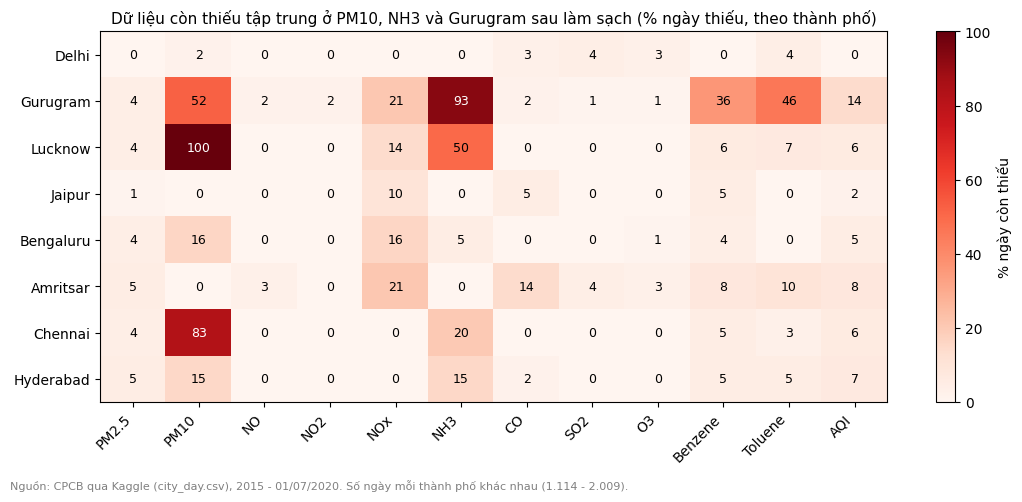

In [11]:
# Biểu đồ: % thiếu còn lại sau làm sạch
fig, ax = plt.subplots(figsize=(11, 5))
data = miss.values
im = ax.imshow(data, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(data.shape[1])); ax.set_xticklabels(miss.columns, rotation=45, ha="right")
ax.set_yticks(range(data.shape[0])); ax.set_yticklabels(miss.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                color="white" if v > 55 else "black", fontsize=9)
ax.set_title("Dữ liệu còn thiếu tập trung ở PM10, NH3 và Gurugram sau làm sạch (% ngày thiếu, theo thành phố)", fontsize=11)
fig.colorbar(im, ax=ax, label="% ngày còn thiếu")
fig.text(0.01, 0.01, "Nguồn: CPCB qua Kaggle (city_day.csv), 2015 - 01/07/2020. Số ngày mỗi thành phố khác nhau (1.114 - 2.009).",
         fontsize=8, color="gray")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f"{REPORTS}/figures/missing_after_cleaning_8cities.png", dpi=150)
plt.show()